# Esfinge, Gradient Boosting

**Aluno:** Pedro Lucas M. S. de Sá

**Professor:** Daniel R. Cassar

**Disciplina:** Aprendizado de Maquina 

Bibliotecas importadas:

In [80]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import LabelEncoder
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor
)
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

## 1. Introdução

Neste notebook didático será explicado e demonstrado um método de Machine Learning chamado de Gradient Boosting.

### 1.1. Objetivo

O objetivo por trás desse notebook é ensinar como o Gradient Boosting funciona tanto na forma de construção do modelo utilizando de modelos mais simples para realizar uma correção nos erros e ir melhorando os modelos a cada passagem até chegar em um modelo final que faz a predição.

### 1.2. Conhecimentos prévios

É esperado que o leitor desse notebook didático saiba o conceito básico de Machine Learning, entenda diferença entre atributos (features) e variável alvo (target), ideia de treinamento e teste, noções de regressão e classificação, funcionamento básico de uma árvore de decisão e noções de Random Forest.

### 1.3. Organização do notebook

Será abordado como funciona árvore de decisão, aprendizado em ensemble, boosting, correção sequencial, função de perda, gradiente e por fim gradient boosting.

### 1.4. Instalação do ucimlrepo

Repositório de demonstração é necessário rodar `pip install ucimlrepo` no terminal, para instalação.

## 2. Relembrando alguns conceitos

Nessa seção irei rever de forma breve alguns conceitos.

### 2.1. Features e target

Os atributos (features) são as características do conjunto de dados que entram no modelo e vão servir para prever a variável alvo (target).

### 2.2. Treinamento e predição

O treinamento é a passagem de dados pelo modelo onde ele aprende uma relação entre as features e o target, assim ele pode prever um target, a partir de novas features.

### 2.3. Erro de uma predição

Após o treinamento ao realizar-se uma previsão de target com algumas features, temos um erro envolvido se compararmos com o valor do target real.

Um exemplo:

$ \text{Target real} = 100$

$ \text{Target previsto} = 90$

$ \text{Erro} = \text{?}$

O erro pode ser calculado de diversas formas como sendo o erro absoluto que é o modulo da diferença entre os targets, pode ser o erro relativo que é calculado pelo modulo da diferença dividido pelo valor real dos targets ou até o erro quadrático que é o quadrado da diferença dos targets. Assim existem diversas formas de analisar o erro.

$ \text{Erro}_{\text{Absoluto}} = |100-90| = 10$

$ \text{Erro}_{\text{Relativo}} = \dfrac{|100-90|}{100} = 0,1$

$ \text{Erro}_{\text{Quadrático}} = (100-90)^2 = 100$


## 3. Árvores de decisão

Árvores de decisão são uma forma de tentar prever um resultado utilizando uma série de tomadas de decisão, como mostra abaixo uma árvore de decisão que ilustra como é realizado a escolha de uma fruta com base em suas características.

Código de árvore de decisão de uma fruta disponível em https://elisaterumi.substack.com/p/arvore-de-decisao-como-tomar-decisoes


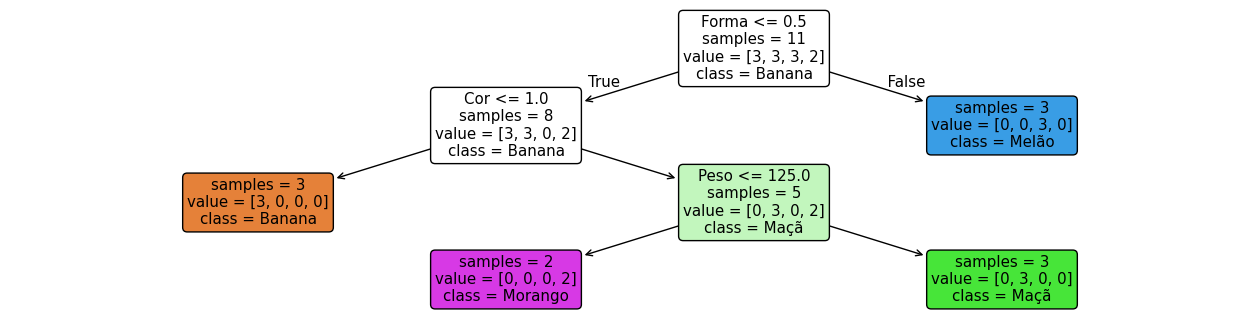

In [81]:
# Gerando dados fictícios sobre frutas
# [Peso (em gramas), Cor (String), Forma (0=Redonda, 1=Alongada)]
X_fruta = np.array([[190, 'Amarela', 'Redonda'],  # Banana, Amarela, Redonda
              [200, 'Vermelha', 'Redonda'],  # Maçã, Vermelha, Redonda
              [220, 'Verde', 'Alongada'],  # Melão, Verde, Alongada
              [180, 'Amarela', 'Redonda'],  # Banana, Amarela, Redonda
              [30, 'Vermelha', 'Redonda'], # Morango, Vermelho, Redondo
              [210, 'Vermelha', 'Redonda'],   # Maçã, Vermelha, Redonda
              [200, 'Verde', 'Alongada'],  # Melão, Verde, Alongada
              [170, 'Amarela', 'Redonda'],  # Banana, Amarela, Redonda
              [210, 'Vermelha', 'Redonda'],  # Maçã, Vermelha, Redonda
              [290, 'Verde', 'Alongada'],    # Melão, Verde, Alongada
              [50, 'Vermelha', 'Redonda']]) # Morango, Vermelho, Redondo

# Rótulos (0=Banana, 1=Maçã, 2=Melão, 3=Morango)
y_fruta = np.array([0, 1, 2, 0, 3, 1, 2, 0, 1, 2, 3])

# Codificando as cores (Label Encoding)
label_encoder = LabelEncoder()
X_fruta[:, 1] = label_encoder.fit_transform(X_fruta[:, 1])  # Codificando a coluna de cores

# Codificando a forma como valores numéricos
X_fruta[:, 2] = np.where(X_fruta[:, 2] == 'Redonda', 0, 1)

# Convertendo os dados de X_fruta para tipo numérico
X_fruta = X_fruta.astype(float)

# Criando o classificador de árvore de decisão
clf = DecisionTreeClassifier(random_state=41)

# Treinando o modelo
clf.fit(X_fruta, y_fruta)

# Visualizando a árvore de decisão
plt.figure(figsize=(16, 4))
plot_tree(clf, filled=True, feature_names=["Peso", "Cor", "Forma"], class_names=["Banana", "Maçã", "Melão", "Morango"], rounded=True, impurity=False)
plt.show()

As árvores de decisão realizam sua previsão com base nos valores das features até chegar em uma folha, onde produz a previsão.

Árvores de decisão podem ser instáveis ​​porque pequenas variações nos dados podem gerar uma árvore completamente diferente. Uma possibilidade de evitar essa instabilidade de uma única árvore é utilizando um ensemble que gera um modelo mais robusto, com a combinação de diferentes modelos, produzindo uma previsão conjunta.

## 4. Ensemble Learning

O ensemble é uma técnica em que utiliza-se de diferentes modelos para conseguir criar uma previsão final. Em que para a criação desses modelos você pode utilizar de bagging ou boosting.

O bagging constrói vários modelos independentes entre si para depois combiná-los e obter uma previsão final combinando todos os modelos. Um exemplo de método que utiliza bagging é Random Forest.

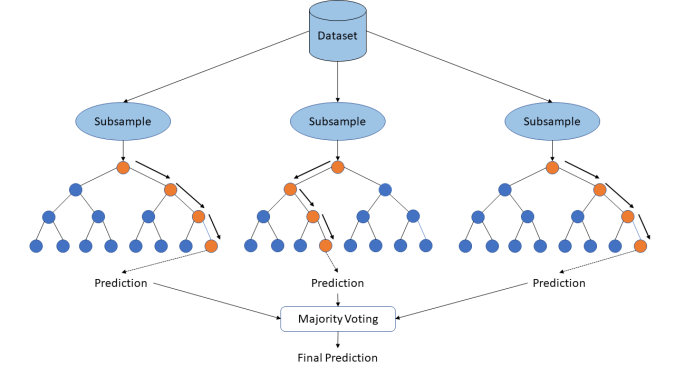

`Imagem 1: Ilustração de um modelo Random Forest que utiliza de árvores de decisão, que combinando a previsão de cada árvore resulta em uma previsão final. Disponível em https://www.researchgate.net/figure/Random-Forest-Algorithm-Dataset-is-split-into-subsamples-and-each-tree-like-structure_fig2_345362070`

Já um modelo construído a partir de boosting, o resultado de um modelo influencia a construção do próximo modelo, de forma que se busca corrigir o erro presente nos modelos anteriores. Um exemplo de método que utiliza de boosting é o gradient boosting.

| Característica        | Bagging                          | Boosting                               |
| ---                   | ---                              | ---                                    |
| Construção            | Independente                     | Sequencial                             |
| Relação entre modelos | Não dependem dos anteriores      | Próximo modelo considera os anteriores |
| Objetivo              | Combinar as previsões dos modelos| Melhorar progressivamente as previsões |
| Exemplo               | Random Forest                    | Gradient Boosting                      |

`Tabela 1: Diferença das características entre Bagging e Boosting`

## 5. Gradient Boosting

O Gradient Boosting se inicia com uma previsão constante que é a média dos targets no caso de regressão de perda quadrática, a partir dessa previsão são calculados os resíduos da previsão e, em seguida, é criada uma árvore de decisão rasa utiliza os atributos e cada folha da árvore fornece uma estimativa de correção com base nos resíduos, esse ajuste é multiplicado pela taxa de aprendizado que é a intensidade da correção aplicada na nova previsão e com esse resultado é realizado a soma com a previsão atual, e esse processo de adição de modelos constrói progressivamente o modelo final.

### 5.1. Inicialização do modelo

A primeira previsão realizada pelo modelo é uma previsão constante que minimize a função de perda, dessa forma para um mesmo conjunto de dados a previsão inicial pode mudar a depender da função de perda utilizada.

$$ F_0(x)=\underset{c}{\arg\min}\sum_{i=1}^{n}L(y_i,c) $$

$F_0(x)$: Previsão inicial

$L(y_i,c)$: Função de perda

$y_i$: Valor real do target da observação $i$

$c$: Valor que minimiza a função de perda

$n$: Número de observações de treinamento

Quando utilizamos a perda quadrática, a previsão inicial ótima corresponde à média dos valores do target no conjunto de treinamento.

Para a perda absoluta, uma mediana dos valores do target minimiza a função de perda. Quando o número de observações é ímpar, a mediana corresponde ao valor central do conjunto ordenado. Quando é par, qualquer valor no intervalo fechado entre os dois valores centrais minimiza a perda absoluta

### 5.2. Resíduos e gradiente negativo

O resíduo é a diferença entre o valor real e o valor previsto pelo modelo, e para calculá-lo, utiliza-se a seguinte equação:

$$ r_{i,m}=y_i-F_{m-1}(x_i) $$

$r_{i,m}$: Resíduo da observação $i$ utilizado na iteração $m$

$y_i$: Valor real do target da observação $i$

$F_{m-1}(x_i)$: Previsão do conjunto de modelos antes da adição da árvore $m$

$x_i$: Atributos da observação $i$

Como inicialmente se utiliza uma previsão constante para todas as observações, a fim de melhorar essa previsão para cada observação, os resíduos orientam o treinamento da próxima árvore, que será adicionada ao conjunto existente.

O gradiente da função de perda serve para encontrar a direção de maior crescimento local da função, enquanto o o gradiente negativo aponta para a direção de maior decrescimento local, e conhecendo a direção de redução da função pode-se encontrar uma nova previsão que a função de perda seja menor que anteriormente, no caso da perda quadrática podemos utilizar diretamente os resíduos, pois eles coincidem com gradiente negativo da função de perda. Essa relação pode ser demonstrada matematicamente:

$$L(y,F)=\frac{1}{2}(y-F)^2$$
$$\frac{\partial L}{\partial F} = -\frac{2}{2}(y-F)= F-y$$
$$-\frac{\partial L}{\partial F} = y-F = r$$

### 5.3. Treinamento das árvores e atualização do modelo

As árvores são treinadas da seguinte forma, elas recebem os atributos e buscam aproximar os gradientes negativos calculados com a previsão anterior, onde as folhas dessas árvores terão o valor dividido pelos nós de forma a reduzir o erro quadrático e os seus valores são dados pela média dos resíduos correspondente a divisão. A incorporação da árvore ao conjunto é feita utilizando dessa atualização:

$$F_m(x)=F_{m-1}(x)+\eta h_m(x)$$

$F_m(x)$: Nova previsão após a interação $m$

$F_{m-1}(x)$: Previsão anterior a interação $m$

$\eta$: Taxa de aprendizado

$h_m(x)$: Correção da árvore treinada na interação $m$

### 5.4. Exemplo didático

Considere o seguinte conjunto de dados $C$, no qual será construído um modelo para prever a variável-alvo $y$ a partir de um atributo $x$. Os dados apresentam uma relação quadrática, definida por $y=x^2$.

| $x$ | $y$ |
|---|---|
| 1 | 1 |
| 2 | 4 |
| 3 | 9 |
| 4 | 16 |
| 5 | 25 |
| 6 | 36 |
| 7 | 49 |

`Tabela 2: Conjunto de dados C, em que o atributo e a variável-alvo apresentam uma relação quadrática.`

Para construir o modelo de Gradient Boosting, será utilizada a função de perda quadrática:

$$
L(y,F)=\frac{1}{2}(y-F)^2
$$

Também será adotada uma taxa de aprendizado (*learning rate*) de $\eta=0,1$, utilizando árvores de regressão de profundidade 1.

A previsão inicial $F_0(x)$ é obtida pela média dos valores da variável-alvo, pois estamos utilizando a função de perda quadrática:

$$
F_0(x)=\frac{1+4+9+16+25+36+49}{7}=20
$$

Assim, a previsão inicial é constante e igual a 20 para todas as observações.

Calculando os resíduos pela diferença entre os valores reais e a previsão inicial, obtemos:

$$
r_{i,1}=[-19; -16; -11; -4; 5; 16; 29]
$$

As perdas individuais correspondentes são:

$$
L=[180,5; 128; 60,5; 8; 12,5; 128; 420,5]
$$

Somando essas perdas, encontramos a perda total inicial:

$$
J(F_0)=938
$$

Para construir a primeira árvore $h_1(x)$, buscamos a divisão que minimiza a soma dos erros quadráticos (SSE) dos resíduos dentro das folhas.

Entre as divisões possíveis, aquela que apresenta o menor SSE é $x\leq4,5$. As correções previstas pelas folhas correspondem às médias dos resíduos de cada grupo, resultando em:

$$
h_1(x)=
\begin{cases}
-12,5, & x\leq4,5\\
16,6667, & x>4,5
\end{cases}
$$

A primeira atualização é realizada pela equação:

$$
F_1(x)=F_0(x)+0,1h_1(x)
$$

Dessa forma, as previsões para as sete observações passam a ser:

$$
F_1(X)=[18,75; 18,75; 18,75; 18,75; 21,6667; 21,6667; 21,6667]
$$

Após essa atualização, a perda total diminui para aproximadamente $799,46$.

Para construir a segunda árvore, calculamos os novos resíduos utilizando as previsões de $F_1(x)$:

$$
r_{i,2}=[-17,75; -14,75; -9,75; -2,75; 3,3333; 14,3333; 27,3333]
$$

Realizando novamente a avaliação das divisões possíveis por meio do SSE, verifica-se que a melhor divisão passa a ser $x\leq5,5$.

As médias dos resíduos das duas folhas fornecem as seguintes correções:

$$
h_2(x)=
\begin{cases}
-8,3333, & x\leq5,5\\
20,8333, & x>5,5
\end{cases}
$$

A segunda atualização é realizada por:

$$
F_2(x)=F_1(x)+0,1h_2(x)
$$

Com isso, obtemos as previsões:

$$
F_2(X)=[17,9167; 17,9167; 17,9167; 17,9167; 20,8333; 23,75; 23,75]
$$

A perda total após essa iteração é aproximadamente $684,01$.

A evolução da função de perda pode ser observada na tabela abaixo:

| Modelo | Perda total |
|---|---|
| $F_0(x)$ | 938,00 |
| $F_1(x)$ | 799,46 |
| $F_2(x)$ | 684,01 |

Após duas iterações, houve uma redução de aproximadamente 27,08% na perda total de treinamento em relação ao modelo inicial.


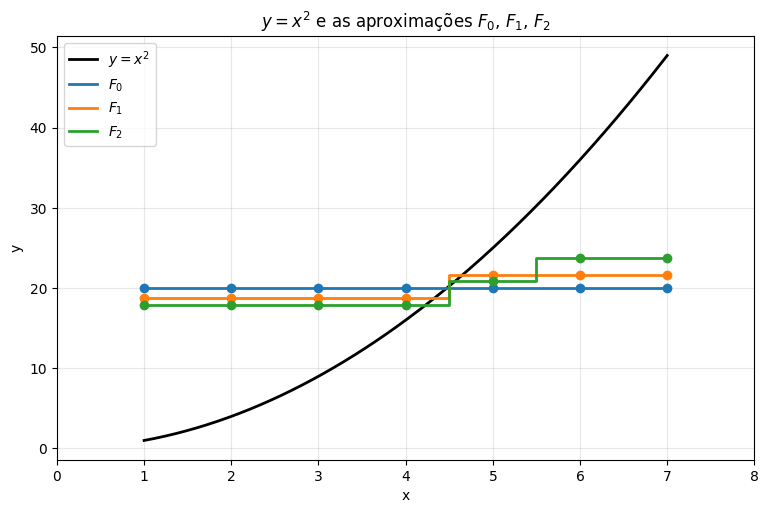

In [82]:
# Previsões
F0 = [20, 20, 20, 20, 20, 20, 20]
F1 = [18.75, 18.75, 18.75, 18.75, 21.667, 21.667, 21.667]
F2 = [17.9167, 17.9167, 17.9167, 17.9167, 20.8333, 23.75, 23.75]

# x^2
x_fino = np.linspace(1, 7, 300)
y = x_fino ** 2

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(x_fino, y, color="black", linewidth=2, label=r"$y = x^2$")

x = np.arange(1, 8)
for valores, nome, cor in [
    (F0, r"$F_0$", "tab:blue"),
    (F1, r"$F_1$", "tab:orange"),
    (F2, r"$F_2$", "tab:green"),
]:
    ax.step(x, valores, where="mid", color=cor, linewidth=2, label=nome)
    ax.plot(x, valores, "o", color=cor)

ax.set_xlim(0, 8)
ax.set_xticks(np.arange(0, 9, 1))
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(r"$y = x^2$ e as aproximações $F_0$, $F_1$, $F_2$")
ax.grid(alpha=0.3)
ax.legend()

plt.show()

O gráfico evidencia que as previsões ainda estão distantes dos valores observados. Isso ocorre devido ao pequeno número de iterações, à profundidade limitada das árvores.

## 6. Aplicação e Treinamento do modelo


### 6.1. Conjunto de dados

O conjunto de dados que será utilizado é o Airfoil Self-Noise [3], em que foram coletados dados com 1503 observações em um túnel de vento sendo 5 atributos numéricos: frequência, ângulo de ataque, comprimento da corda, velocidade do fluxo livre e espessura de deslocamento da camada limite no lado de sucção. e a variável alvo: nível de pressão sonora (dB).

Na célula abaixo segue o código recomendado pela UCI [3] para o carregamento dos dados:

In [83]:
airfoil = fetch_ucirepo(id=291)

X = airfoil.data.features
y = airfoil.data.targets

print(X.describe())
print()
print(y.describe())

          frequency  attack-angle  chord-length  free-stream-velocity  \
count   1503.000000   1503.000000   1503.000000           1503.000000   
mean    2886.380572      6.782302      0.136548             50.860745   
std     3152.573137      5.918128      0.093541             15.572784   
min      200.000000      0.000000      0.025400             31.700000   
25%      800.000000      2.000000      0.050800             39.600000   
50%     1600.000000      5.400000      0.101600             39.600000   
75%     4000.000000      9.900000      0.228600             71.300000   
max    20000.000000     22.200000      0.304800             71.300000   

       suction-side-displacement-thickness  
count                          1503.000000  
mean                              0.011140  
std                               0.013150  
min                               0.000401  
25%                               0.002535  
50%                               0.004957  
75%                        

Analisando as estatísticas descritivas do conjunto de dados, observa-se que não existem valores ausentes. Além disso, a velocidade do fluxo livre apresenta o primeiro quartil e a mediana iguais a 39,6 m/s, indicando uma concentração das observações em determinados valores.

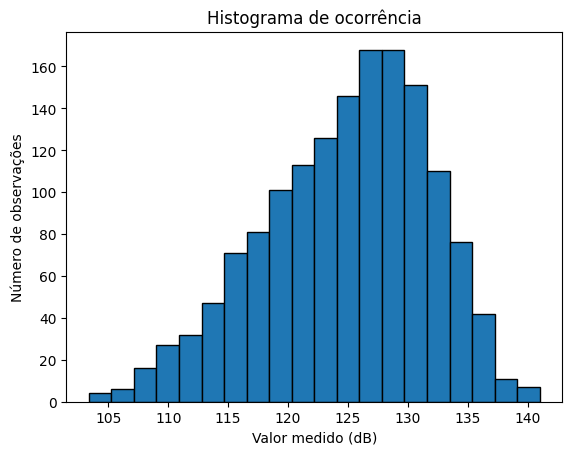

In [84]:
plt.hist(y, bins=20, edgecolor="black")
plt.xlabel("Valor medido (dB)")
plt.ylabel("Número de observações")
plt.title("Histograma de ocorrência")
plt.show()

A partir do histograma da variável-alvo, observa-se uma maior concentração dos níveis de pressão sonora entre aproximadamente 120 e 135 dB, com maior frequência próxima de 127 a 130 dB.

### 6.2. Treinamento do modelo

Inicialmente será realizado a separação de conjunto de treino e conjunto de teste, com uma divisão de 20% para teste.

In [85]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)


Para o treinamento inicial do Gradient Boosting, serão utilizadas 100 árvores de regressão, uma taxa de aprendizado de $0,1$ e profundidade máxima de 3. Esses valores foram escolhidos como ponto de partida, permitindo realizar correções sucessivas nas previsões e limitar a complexidade das árvores.

Além disso, será utilizada uma semente aleatória (`SEMENTE_ALEATORIA=42`) para favorecer a reprodutibilidade dos resultados. A influência dos hiperparâmetros sobre o desempenho do modelo será investigada posteriormente.

In [86]:
SEMENTE_ALEATORIA=42

modelo = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=SEMENTE_ALEATORIA
)

modelo.fit(X_treino, y_treino.to_numpy().ravel())


,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


## 7. Avaliação, visualizações e análise

### 7.1. Métricas de avaliação

Para avaliação do modelo será utilizado das métricas de MAE e RMSE.

Na célula abaixo segue o código para encontrar o MAE e RMSE:

In [87]:
y_pred_treino = modelo.predict(X_treino)
y_pred_teste = modelo.predict(X_teste)

# MAE
mae_treino = mean_absolute_error(y_treino, y_pred_treino)
mae_teste = mean_absolute_error(y_teste, y_pred_teste)

# RMSE
rmse_treino = root_mean_squared_error(y_treino, y_pred_treino)
rmse_teste = root_mean_squared_error(y_teste, y_pred_teste)

print(f"MAE treino: {mae_treino:.4f} dB")
print(f"MAE teste: {mae_teste:.4f} dB")
print(f"RMSE treino: {rmse_treino:.4f} dB")
print(f"RMSE teste: {rmse_teste:.4f} dB")

print("----")
print("Baseline")

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_treino, y_treino)

y_pred_baseline = baseline.predict(X_teste)

mae_baseline = mean_absolute_error(y_teste, y_pred_baseline)
rmse_baseline = root_mean_squared_error(y_teste, y_pred_baseline)

print(f"MAE baseline: {mae_baseline:.4f} dB")
print(f"RMSE baseline: {rmse_baseline:.4f} dB")


MAE treino: 1.7814 dB
MAE teste: 2.1689 dB
RMSE treino: 2.3691 dB
RMSE teste: 2.8609 dB
----
Baseline
MAE baseline: 5.7917 dB
RMSE baseline: 7.0810 dB


O MAE no conjunto de teste, as previsões apresentam um erro absoluto médio de aproximadamente 2,17 dB em relação aos valores observados.O RMSE tem o valor de aproximadamente 2,86 dB indicando que, ao penalizar mais intensamente os erros maiores, a métrica produz um resultado superior ao MAE. Isso é esperado devido à maneira como o RMSE é calculado.

Há uma diferença entre os erros de treinamento e teste, mas o desempenho em teste continua significativamente melhor que o baseline, que indica um modelo com capacidade de generalização razoável.

### 7.2. Visualização de resultados



Para uma visualização do comportamento das previsões será realizado dois gráficos um de valores reais por previstos e outro de resíduos por previstos.

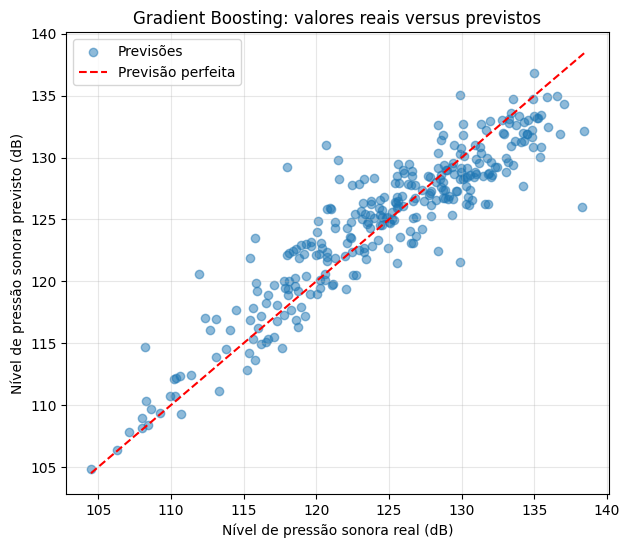

In [88]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_teste.iloc[:, 0],
    y_pred_teste,
    alpha=0.5,
    label="Previsões"
)

limite_min = min(y_teste.iloc[:, 0].min(), y_pred_teste.min())
limite_max = max(y_teste.iloc[:, 0].max(), y_pred_teste.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--",
    color="red",
    label="Previsão perfeita"
)

plt.xlabel("Nível de pressão sonora real (dB)")
plt.ylabel("Nível de pressão sonora previsto (dB)")
plt.title("Gradient Boosting: valores reais versus previstos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


O gráfico de valores reais por previstos indica que modelo tem uma boa acurácia, mas com comportamento de superestimação em regiões como de 120 a 125, enquanto próxima a 130 uma subestimação.

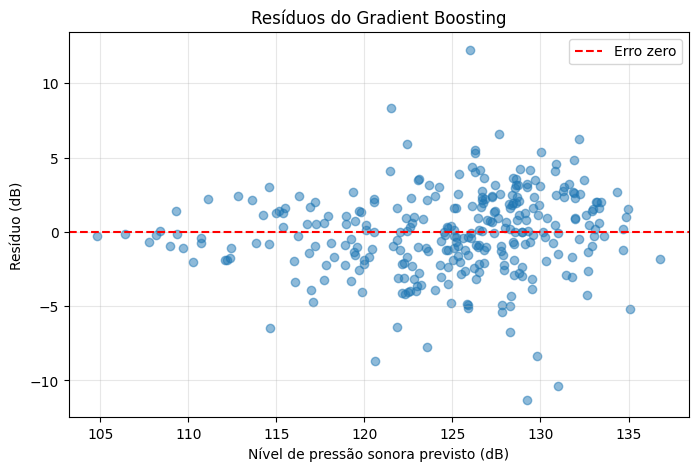

In [89]:
residuos = y_teste.iloc[:, 0].to_numpy() - y_pred_teste

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_teste,
    residuos,
    alpha=0.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Erro zero"
)

plt.xlabel("Nível de pressão sonora previsto (dB)")
plt.ylabel("Resíduo (dB)")
plt.title("Resíduos do Gradient Boosting")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Os resíduos estão distribuídos dos dois lados da linha de erro zero, sem uma tendência sistemática evidente. Entretanto, sua dispersão parece aumentar para determinados intervalos de pressão sonora prevista, especialmente entre 120 e 135 dB. Além disso, existem algumas observações com resíduos superiores a 10 dB em magnitude, indicando que o modelo ainda apresenta erros elevados em determinadas previsões.

### 7.3. Influência dos hiperparâmetros 

Os hiperparâmetros do Gradient Boosting influenciam o treinamento e a complexidade do modelo. Entre os principais estão o número de árvores (`n_estimators`), a taxa de aprendizado (`learning_rate`) e a profundidade máxima das árvores (`max_depth`).

Para demonstrar essa influência, será realizado um experimento variando apenas o número de árvores entre 10, 100 e 300, mantendo a taxa de aprendizado em $0,1$ e a profundidade máxima em 3.

O desempenho será avaliado por meio do RMSE nos conjuntos de treinamento e validação. O conjunto de teste não será utilizado para escolher os hiperparâmetros.

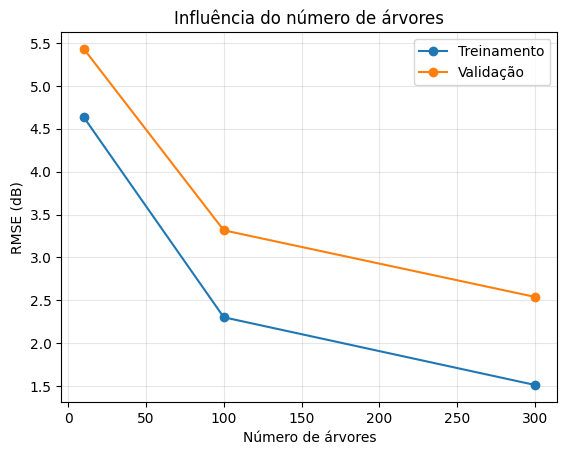

In [90]:
# Separar parte do treino para validação
X_tr, X_val, y_tr, y_val = train_test_split(
    X_treino, y_treino,
    test_size=0.2,
    random_state=SEMENTE_ALEATORIA
)

valores_arvores = [10, 100, 300]

erros_treino = []
erros_validacao = []

for n in valores_arvores:
    modelo_experimento = GradientBoostingRegressor(
        n_estimators=n,
        learning_rate=0.1,
        max_depth=3,
        random_state=SEMENTE_ALEATORIA
    )

    modelo_experimento.fit(X_tr, y_tr.to_numpy().ravel())

    pred_treino = modelo_experimento.predict(X_tr)
    pred_val = modelo_experimento.predict(X_val)

    erros_treino.append(
        root_mean_squared_error(y_tr, pred_treino)
    )
    erros_validacao.append(
        root_mean_squared_error(y_val, pred_val)
    )

plt.plot(valores_arvores, erros_treino,
         marker="o", label="Treinamento")
plt.plot(valores_arvores, erros_validacao,
         marker="o", label="Validação")

plt.xlabel("Número de árvores")
plt.ylabel("RMSE (dB)")
plt.title("Influência do número de árvores")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


O gráfico evidencia que o aumento do número de árvores de 10 para 300 reduziu o RMSE tanto no conjunto de treinamento quanto no de validação. Embora o erro de treinamento permaneça menor que o de validação, não foi observado um aumento do RMSE de validação que caracterizasse uma piora da generalização nesse intervalo. Portanto, entre as três configurações analisadas, o modelo com 300 árvores apresentou o menor RMSE de validação.

### 7.4. Comparação com Random Forest

Abaixo segue o código para analise comparativa do Gradient Boosting com Random Forest.

In [91]:
modelos = {
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=SEMENTE_ALEATORIA
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=3,
        random_state=SEMENTE_ALEATORIA
    )
}

for nome, modelo_comparacao in modelos.items():
    modelo_comparacao.fit(X_tr, y_tr.to_numpy().ravel())

    previsoes = modelo_comparacao.predict(X_val)

    rmse = root_mean_squared_error(y_val, previsoes)

    print(f"{nome}: RMSE = {rmse:.4f} dB")


Gradient Boosting: RMSE = 3.3161 dB
Random Forest: RMSE = 5.2529 dB


O Gradient Boosting apresentou menor RMSE de validação que a Random Forest nas configurações avaliadas. Uma possível explicação está na estratégia de treinamento sequencial do Gradient Boosting, que permite adicionar árvores para corrigir progressivamente os erros do conjunto. Além disso, a profundidade máxima de 3 pode ter limitado a capacidade preditiva da Random Forest. Entretanto, não é possível afirmar que o Gradient Boosting seja universalmente superior, pois os resultados dependem dos hiperparâmetros e das características dos dados.

## 8. Conclusão

O Gradient Boosting é um algoritmo de aprendizado de máquina que utiliza árvores de decisão treinadas sequencialmente para corrigir os erros das previsões anteriores. A profundidade das árvores influencia a complexidade do modelo, podendo permitir o aprendizado de relações mais complexas, mas também aumentar o risco de overfitting.

No conjunto de dados Airfoil Self-Noise, o Gradient Boosting apresentou um RMSE de $2,8609$ dB no conjunto de teste, enquanto o baseline apresentou $7,0810$ dB, demonstrando uma redução significativa do erro de previsão.

Além disso, no experimento sobre a influência dos hiperparâmetros, o aumento do número de árvores de 10 para 300 reduziu o RMSE tanto no treinamento quanto na validação, sem evidências de agravamento do overfitting nesse intervalo.

O Gradient Boosting também demonstrou bom desempenho preditivo em comparação com a Random Forest, apresentando um RMSE de validação inferior quando ambos os modelos utilizaram 100 árvores com profundidade máxima de 3. Entretanto, esse resultado não permite afirmar que o Gradient Boosting seja sempre superior à Random Forest, pois o desempenho depende dos hiperparâmetros e das características dos dados.

## 9. Descrição do uso de IA neste trabalho

Foi utilizada inteligência artificial, por meio do ChatGPT, para auxiliar na pesquisa, na compreensão dos conceitos e na orientação do desenvolvimento deste notebook.

A ferramenta também foi utilizada para revisar explicações matemáticas, corrigir e aprimorar textos e auxiliar na interpretação dos resultados experimentais. Grande parte dos códigos utilizados foi elaborada com auxílio da IA.

Durante o desenvolvimento, os conceitos foram discutidos por meio de perguntas e exercícios, enquanto os códigos foram executados e seus resultados analisados pelo autor.

E antes da entrega foi realizado uma passagem do notebook pela IA.

Link da conversa: https://chatgpt.com/share/6ad6038e-3a74-83e8-ab20-4143c84d9cfc

## 10. Referências

[1] Fundamentação teórica do Gradient Boosting	Friedman, J. H. (2001). Greedy Function Approximation: A Gradient Boosting Machine. The Annals of Statistics, 29(5), 1189–1232. DOI do artigo: https://doi.org/10.1214/aos/1013203451.

[2] Implementação do Gradient Boosting	Documentação oficial do GradientBoostingRegressor. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html.

[3] Conjunto de dados	Brooks, T., Pope, D., & Marcolini, M. (1989). Airfoil Self-Noise [Dataset]. UCI Machine Learning Repository. DOI do conjunto de dados: https://doi.org/10.24432/C5VW2C.

[4] Random Forest	Documentação oficial do RandomForestRegressor. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html.
